Time Series Stationary Process
-
1. milk dataset
2. FRED-NROUST dataset
3. Air Passsengers dataset
4. BUNDESBANK dataset

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose # pip install statsmodels
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.stattools import adfuller
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

Milk Dataset
-

In [2]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv")
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


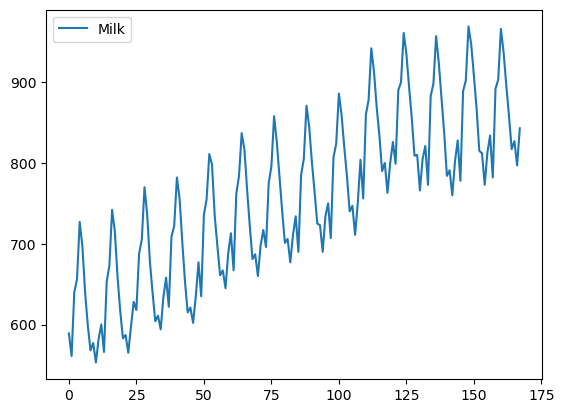

In [3]:
df.plot()
plt.show()

No, maxlag=10 should not always remain the same. It is a parameter that depends heavily on your dataset's frequency, size, and the nature of the "memory" in your data.

By setting maxlag=10, you are forcing the test to check if the current value is correlated with up to 10 previous time steps to account for higher-order serial correlation

Frequency  |   Typical maxlag |   Reason
Quarterly  |   4 or 8         | Covers 1 or 2 full annual cycles.
Monthly    |   12 or 24       |  Covers 1 or 2 full years.
Daily      |   7 or 30        |  Covers a week or a month.

In [4]:
result = adfuller(df['Milk'], maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 0.6443832606930107
Time Series is not stationary


In [15]:
diff_1 =df['Milk'].diff()[1:]
result = adfuller(diff_1, maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 0.0
Time Series is stationary


Fred-Nroust Dataset
-

In [5]:
df1 = pd.read_csv("FRED-NROUST.csv")
df1

,Date,Value
0,01-01-1949,5.255053
1,01-04-1949,5.261516
2,01-07-1949,5.268013
3,01-10-1949,5.274564
4,01-01-1950,5.281182
...,...,...
291,01-10-2021,4.450651
292,01-01-2022,4.445137
293,01-04-2022,4.440214
294,01-07-2022,4.435784


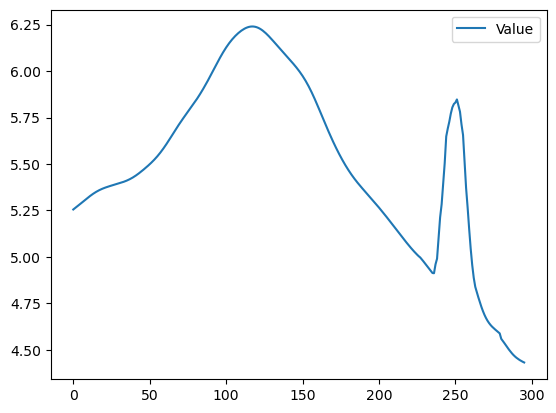

In [6]:
df1.plot()
plt.show()

Code to check Time Series is stationary or not
-

In [7]:
result = adfuller(df1['Value'], maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 0.8679327286496508
Time Series is not stationary


Convert Not Stationary to Stationary by First-Order Differencing
--

In [ ]:
diff_2 =df1['Value'].diff()[1:] 
result = adfuller(diff_2, maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 0.0003846984987886586
Time Series is stationary


[1:] => Removes the very first row. Because the first row has no "previous" value to subtract from, it becomes NaN (Not a Number). Statistical tests like adfuller will crash if they see a NaN.

AirPassengers Dataset
-

In [8]:
df2 = pd.read_csv("AirPassengers.csv")
df2

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


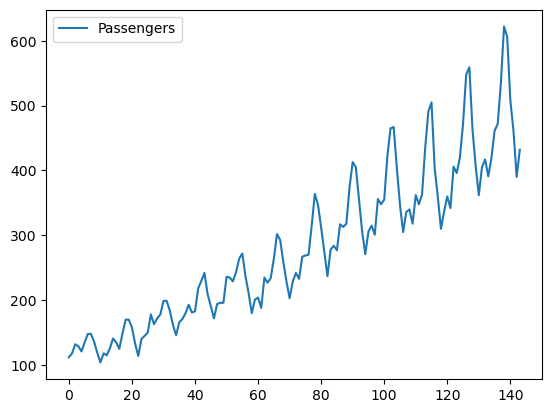

In [9]:
df2.plot()
plt.show()

In [10]:
result = adfuller(df2['Passengers'], maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 0.998969450186538
Time Series is not stationary


In [17]:
diff_3 = df2['Passengers'].diff()[1:]
result = adfuller(diff_3, maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 8.67487685327193e-29
Time Series is stationary


BUNDESBANK Dataset
-

In [11]:
df3 = pd.read_csv("BUNDESBANK-BBK01_WT5511.csv")
df3

,Date,Value
0,30-04-1968,39.10
1,31-05-1968,42.00
2,30-06-1968,40.95
3,31-07-1968,38.90
4,31-08-1968,39.85
...,...,...
572,31-12-2015,1062.25
573,31-01-2016,1112.90
574,29-02-2016,1234.15
575,31-03-2016,1233.60


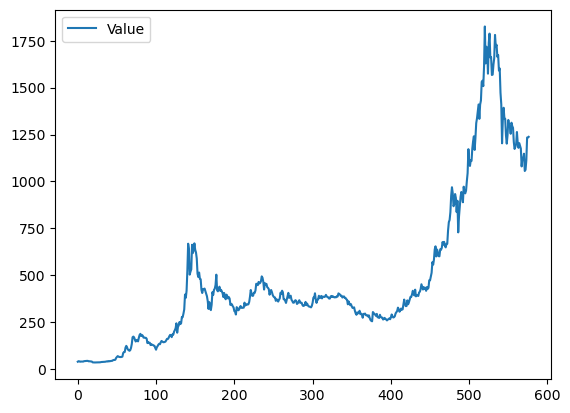

In [12]:
df3.plot()
plt.show()

In [14]:
result = adfuller(df3['Value'], maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 0.8657686355517233
Time Series is not stationary


In [18]:
diff_4 = df3['Value'].diff()[1:]
result = adfuller(diff_4, maxlag=10)
print("P-value =", result[1])
if result[1] < 0.05:
    print("Time Series is stationary")
else:
    print("Time Series is not stationary")

P-value = 2.590139409017334e-06
Time Series is stationary
